# 🗞️ Tarea 1 – Parte 1: Recolección, limpieza y EDA

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Parámetro | Valor |
| :--- | :--- |
| **Fecha de descarga** | 18 de octubre de 2026 (se registra automáticamente en la celda de configuración) |
| **Opción elegida** | **C – Comparada** (200 noticias de La República + 200 de El Comercio) |
| **Categorías** | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| **URL base La República** | https://larepublica.pe |
| **URL base El Comercio** | https://elcomercio.pe |

**Fuentes concretas utilizadas**

| Medio | Fuente | URLs |
| :--- | :--- | :--- |
| La República | RSS oficiales | `https://larepublica.pe/rss/{home,politica,economia,deportes,ciencia}.xml` |
| La República | Portadas de sección (JSON `__NEXT_DATA__` embebido en el HTML) | `https://larepublica.pe/{politica,economia,deportes,ciencia,tecnologia}` |
| La República | Páginas de artículo → bloque "más noticias de la sección" | `https://larepublica.pe/<seccion>/AAAA/MM/DD/<slug>` |
| El Comercio | RSS oficiales (Arc Publishing) | `https://elcomercio.pe/arc/outboundfeeds/rss/category/{politica,economia,deporte-total,tecnologia}/` |
| El Comercio | Sitemaps web por sección + metadatos `og:` del HTML de cada artículo | `https://elcomercio.pe/sitemap/web/<seccion>/?outputType=xml` |

**Buenas prácticas aplicadas**
- Se descarga y **se interpreta el `robots.txt`** de cada medio (con soporte de comodines `*`), y toda URL se valida antes de pedirse.
  La República **prohíbe la paginación** (`Disallow: /*/pag/`), por eso no se recorren páginas 2, 3, …; en su lugar se usan los RSS
  (explícitamente permitidos: `Allow: /rss/`) y los enlaces "más noticias de la sección" de cada artículo.
- `User-Agent` descriptivo, **pausa aleatoria de 1 a 2 s** entre solicitudes y **máximo 1 reintento**.
- Respaldo crudo en `datos/raw/`. Si el respaldo existe, el notebook lo reutiliza (`USAR_RESPALDO = True`) para no volver a
  golpear los servidores y para que la ejecución sea reproducible aunque cambie el HTML de los medios.

In [1]:
import html
import json
import random
import re
import time
from datetime import datetime, timedelta, timezone
from email.utils import parsedate_to_datetime
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup

# Interactivo en VS Code/Jupyter y PNG estático para que se vea en GitHub
pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 120)

FECHA_DESCARGA = datetime.now(timezone(timedelta(hours=-5))).strftime("%Y-%m-%d %H:%M (UTC-5)")
OPCION = "C – Comparada (La República + El Comercio)"
BASES = {"La Republica": "https://larepublica.pe", "El Comercio": "https://elcomercio.pe"}
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

META_POR_CATEGORIA = 60   # se recolecta un excedente para cubrir descartes
FINAL_POR_CATEGORIA = 50  # 50 x 4 categorías = 200 por medio, 400 en total
USAR_RESPALDO = True

DIR_DATOS = Path("datos")
DIR_RAW = DIR_DATOS / "raw"
DIR_RAW.mkdir(parents=True, exist_ok=True)

USER_AGENT = "TareaNLP-Diplomatura-PythonIntermedio/1.0 (proyecto academico; clasificacion de titulares; 1 solicitud cada 1-2 s)"
SESSION = requests.Session()
SESSION.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})

print("Fecha de descarga:", FECHA_DESCARGA)
print("Opción:", OPCION)

Fecha de descarga: 2026-10-18 20:05 (UTC-5)
Opción: C – Comparada (La República + El Comercio)


## 1. Utilidades: solicitudes respetuosas y `robots.txt`

In [2]:
def get(url):
    """GET con pausa aleatoria de 1-2 s y como máximo 1 reintento. Devuelve None si falla."""
    for intento in range(2):
        try:
            r = SESSION.get(url, timeout=30)
            time.sleep(random.uniform(1, 2))
            if r.status_code == 200:
                if "charset" not in r.headers.get("Content-Type", "").lower():
                    r.encoding = "utf-8"
                return r
            if r.status_code in (403, 404, 410):
                return None  # no tiene sentido reintentar
        except requests.RequestException as e:
            print(f"  ! error en intento {intento + 1}: {e.__class__.__name__}")
            time.sleep(random.uniform(1, 2))
    return None


def cargar_robots(base):
    """Devuelve las reglas (allow, patrón) que aplican al grupo `User-agent: *`."""
    r = get(base + "/robots.txt")
    (DIR_RAW / f"robots_{urlparse(base).netloc}.txt").write_text(r.text, encoding="utf-8")
    reglas, agentes, en_reglas = [], [], False
    for linea in r.text.splitlines():
        linea = linea.split("#")[0].strip()
        if ":" not in linea:
            continue
        campo, valor = [x.strip() for x in linea.split(":", 1)]
        campo = campo.lower()
        if campo == "user-agent":
            if en_reglas:
                agentes, en_reglas = [], False
            agentes.append(valor)
        elif campo in ("allow", "disallow"):
            en_reglas = True
            if "*" in agentes and valor:
                reglas.append((campo == "allow", valor))
    return reglas


def permitido(url, reglas):
    """Aplica la regla más específica (patrón más largo); los comodines `*` y `$` se respetan."""
    p = urlparse(url)
    ruta = p.path + ("?" + p.query if p.query else "")
    mejor = None
    for allow, patron in reglas:
        rx = "^" + re.escape(patron).replace(r"\*", ".*")
        rx = rx[:-2] + "$" if rx.endswith(r"\$") else rx
        if re.match(rx, ruta) and (mejor is None or len(patron) > len(mejor[1]) or (len(patron) == len(mejor[1]) and allow)):
            mejor = (allow, patron)
    return True if mejor is None else mejor[0]


ROBOTS = {medio: cargar_robots(base) for medio, base in BASES.items()}
for medio, reglas in ROBOTS.items():
    print(f"{medio}: {len(reglas)} reglas para User-agent: *")

# Verificación rápida del intérprete de robots.txt
pruebas = [
    "https://larepublica.pe/rss/politica.xml",
    "https://larepublica.pe/economia",
    "https://larepublica.pe/economia/pag/2",
    "https://larepublica.pe/buscador?q=dolar",
    "https://elcomercio.pe/sitemap/web/politica/?outputType=xml",
    "https://elcomercio.pe/buscar/congreso",
]
pd.DataFrame({"url": pruebas, "permitido": [permitido(u, ROBOTS["La Republica" if "larepublica" in u else "El Comercio"]) for u in pruebas]})

La Republica: 27 reglas para User-agent: *
El Comercio: 4 reglas para User-agent: *


,url,permitido
0,https://larepublica.pe/rss/politica.xml,True
1,https://larepublica.pe/economia,True
2,https://larepublica.pe/economia/pag/2,False
3,https://larepublica.pe/buscador?q=dolar,False
4,https://elcomercio.pe/sitemap/web/politica/?outputType=xml,True
5,https://elcomercio.pe/buscar/congreso,False


## 2. Funciones de extracción

In [3]:
def limpiar_texto(t):
    if not t:
        return ""
    t = html.unescape(BeautifulSoup(str(t), "html.parser").get_text(" "))
    return re.sub(r"\s+", " ", t).strip()


def fecha_iso(valor):
    """Normaliza RFC-822 (RSS) o ISO-8601 a AAAA-MM-DD en hora de Perú (UTC-5)."""
    if not valor:
        return None
    try:
        dt = parsedate_to_datetime(valor)
    except (TypeError, ValueError):
        try:
            dt = datetime.fromisoformat(str(valor).replace("Z", "+00:00"))
        except ValueError:
            return None
    if dt.tzinfo is not None:
        dt = dt.astimezone(timezone(timedelta(hours=-5)))
    return dt.date().isoformat()


def seccion_desde_url(url):
    """Sección tal como figura en la URL del diario (p. ej. 'politica/partidos', 'economia/precio-del-dolar')."""
    partes = [p for p in urlparse(url).path.split("/") if p]
    if "larepublica.pe" in url:
        seccion = []
        for p in partes:
            if re.fullmatch(r"\d{4}", p):
                break
            seccion.append(p)
        return "/".join(seccion)
    return "/".join(partes[:-1])  # El Comercio: /seccion/subseccion/slug-noticia/


def registro(titular, bajada, medio, url, fecha, fuente):
    url = url.split("?")[0].strip()
    return {
        "titular": limpiar_texto(titular),
        "bajada": limpiar_texto(bajada),
        "medio": medio,
        "seccion_original": seccion_desde_url(url),
        "url": url,
        "fecha": fecha_iso(fecha),
        "fuente_extraccion": fuente,
    }


def leer_rss(url, medio, nombre_respaldo):
    if not permitido(url, ROBOTS[medio]):
        print("  robots.txt no permite", url)
        return []
    r = get(url)
    if r is None:
        print("  sin respuesta", url)
        return []
    (DIR_RAW / "rss").mkdir(exist_ok=True)
    (DIR_RAW / "rss" / nombre_respaldo).write_bytes(r.content)
    soup = BeautifulSoup(r.content, "xml")
    return [
        registro(it.title.get_text() if it.title else "",
                 it.description.get_text() if it.description else "",
                 medio,
                 it.link.get_text() if it.link else "",
                 it.pubDate.get_text() if it.pubDate else None,
                 "rss")
        for it in soup.find_all("item")
    ]


def next_data(html_text):
    m = re.search(r'<script id="__NEXT_DATA__"[^>]*>(.*?)</script>', html_text, re.S)
    return json.loads(m.group(1))["props"]["pageProps"] if m else {}


PATRON_SLUG_LR = re.compile(r"^/[a-z0-9-]+(?:/[a-z0-9-]+)*/\d{4}/\d{2}/\d{2}/[^/]+$")


def cosechar_lr(obj, fuente):
    """Recorre el JSON de Next.js y devuelve todo objeto con forma de artículo (title + slug)."""
    encontrados = []
    if isinstance(obj, dict):
        if isinstance(obj.get("title"), str) and isinstance(obj.get("slug"), str) and PATRON_SLUG_LR.match(obj["slug"]):
            teaser = (obj.get("data") or {}).get("teaser") if isinstance(obj.get("data"), dict) else None
            encontrados.append(registro(obj["title"], teaser, "La Republica",
                                        "https://larepublica.pe" + obj["slug"], obj.get("date"), fuente))
        for v in obj.values():
            encontrados += cosechar_lr(v, fuente)
    elif isinstance(obj, list):
        for v in obj:
            encontrados += cosechar_lr(v, fuente)
    return encontrados


def meta(soup, **attrs):
    tag = soup.find("meta", attrs=attrs)
    return tag.get("content") if tag else None


def leer_articulo_ec(url):
    r = get(url)
    if r is None:
        return None
    soup = BeautifulSoup(r.text, "html.parser")
    titular = meta(soup, property="og:title") or (soup.h1.get_text() if soup.h1 else "")
    titular = re.sub(r"\s*\|\s*El Comercio.*$", "", titular or "")
    bajada = meta(soup, property="og:description") or meta(soup, name="description")
    fecha = meta(soup, property="article:published_time")
    return registro(titular, bajada, "El Comercio", url, fecha, "sitemap+html")

## 3. Mapeo explícito `seccion_original` → categoría

El mapeo se decide por el **primer segmento** de la sección del diario. Todo lo que no entra en estas reglas
(sociedad, mundo, espectáculos, Lima, opinión general, etc.) se **descarta** y se reporta; no se crea una quinta categoría.

In [4]:
MAPA_SECCIONES = {
    "politica": "politica",                 # LR y EC
    "economia": "economia",                 # LR y EC (incluye subsecciones: mercados, precio-del-dolar, dia-1...)
    "deportes": "deportes",                 # LR
    "deporte-total": "deportes",            # EC
    "ciencia": "ciencia_tecnologia",        # LR
    "tecnologia": "ciencia_tecnologia",     # LR y EC (incluye ciencias, inteligencia-artificial, videojuegos...)
}


def mapear(seccion_original):
    return MAPA_SECCIONES.get((seccion_original or "").split("/")[0])


pd.DataFrame([{"primer segmento de la sección": k, "etiqueta": v} for k, v in MAPA_SECCIONES.items()])

,primer segmento de la sección,etiqueta
0,politica,politica
1,economia,economia
2,deportes,deportes
3,deporte-total,deportes
4,ciencia,ciencia_tecnologia
5,tecnologia,ciencia_tecnologia


## 4. Extracción – La República

1. RSS oficiales (`home` se incluye a propósito: trae noticias de otras secciones que luego se descartan).
2. Portadas de sección: el HTML trae embebido un JSON (`__NEXT_DATA__`) con titular, bajada (`teaser`), fecha y URL.
3. Como la paginación está prohibida en `robots.txt`, para completar ~60 noticias por categoría se visitan páginas de artículos
   de la categoría con menos noticias y se recogen sus bloques "más noticias de la sección" (`sectionArticles`, `everGreenArticles`).

In [5]:
def recolectar_lr(max_paginas_articulo=300):
    medio, base = "La Republica", BASES["La Republica"]
    crudos = []
    for nombre in ["home", "politica", "economia", "deportes", "ciencia"]:
        items = leer_rss(f"{base}/rss/{nombre}.xml", medio, f"lr_{nombre}.xml")
        print(f"RSS {nombre:<10} {len(items):>3} ítems")
        crudos += items

    for seccion in ["politica", "economia", "deportes", "ciencia", "tecnologia"]:
        url = f"{base}/{seccion}"
        r = get(url) if permitido(url, ROBOTS[medio]) else None
        if r is None:
            continue
        datos_seccion = next_data(r.text).get("section_data", {})
        items = cosechar_lr(datos_seccion, "portada_seccion")
        print(f"Portada {seccion:<10} {len(items):>3} artículos")
        crudos += items

    # Los bloques de relacionados no traen bajada: al visitar el artículo se obtiene su bajada real
    # (article_internal) y, de paso, nuevos enlaces de la misma sección. Solo cuentan las noticias completas.
    visitadas = set()
    for i in range(max_paginas_articulo):
        todos = pd.DataFrame(crudos)
        todos["cat"] = todos["seccion_original"].map(mapear)
        completos = todos[todos["bajada"] != ""].drop_duplicates("url")
        conteo = completos["cat"].value_counts().reindex(CATEGORIAS, fill_value=0)
        pendientes = [c for c in conteo.sort_values().index if conteo[c] < META_POR_CATEGORIA]
        candidata = None
        for cat in pendientes:
            # Primero los artículos sin bajada (visitarlos los completa); luego cualquiera no visitado (para cosechar más)
            opciones = todos[(todos["cat"] == cat) & ~todos["url"].isin(visitadas)].copy()
            opciones["completo"] = opciones["url"].isin(completos["url"])
            opciones = opciones.sort_values("completo", kind="stable")["url"].drop_duplicates()
            opciones = [u for u in opciones if permitido(u, ROBOTS[medio])]
            if opciones:
                candidata, cat_objetivo = opciones[0], cat
                break
        if candidata is None:
            break
        visitadas.add(candidata)
        r = get(candidata)
        if r is None:
            continue
        pp = next_data(r.text)
        nuevos = cosechar_lr(pp.get("article_internal"), "articulo")
        for clave in ["sectionArticles", "everGreenArticles"]:
            nuevos += cosechar_lr(pp.get(clave), "relacionados_seccion")
        crudos += nuevos
        if i % 25 == 0:
            print(f"  página {i:>3} ({cat_objetivo}): noticias completas por categoría {conteo.to_dict()}")
    print(f"Páginas de artículo visitadas: {len(visitadas)} | completas finales: {conteo.to_dict()}")
    return crudos


def recolectar_ec(max_por_categoria=80):
    medio, base = "El Comercio", BASES["El Comercio"]
    crudos = []
    items = leer_rss(f"{base}/arc/outboundfeeds/rss/?outputType=xml", medio, "ec_home.xml")
    print(f"RSS home          {len(items):>3} ítems")
    crudos += items
    for seccion in ["politica", "economia", "deporte-total", "tecnologia"]:
        items = leer_rss(f"{base}/arc/outboundfeeds/rss/category/{seccion}/?outputType=xml", medio, f"ec_{seccion}.xml")
        print(f"RSS {seccion:<14} {len(items):>3} ítems")
        crudos += items

    for seccion in ["politica", "economia", "deporte-total", "tecnologia"]:
        cat = mapear(seccion)
        url_sitemap = f"{base}/sitemap/web/{seccion}/?outputType=xml"
        r = get(url_sitemap) if permitido(url_sitemap, ROBOTS[medio]) else None
        if r is None:
            continue
        (DIR_RAW / "rss" / f"ec_sitemap_{seccion}.xml").write_bytes(r.content)
        urls = [loc.get_text().strip() for loc in BeautifulSoup(r.content, "xml").find_all("loc")]
        vistos = {c["url"] for c in crudos}
        n_cat = sum(1 for u in vistos if mapear(seccion_desde_url(u)) == cat)
        pedidos = 0
        for url in urls:
            if n_cat >= META_POR_CATEGORIA or pedidos >= max_por_categoria:
                break
            if url in vistos or not url.endswith("-noticia/") or not permitido(url, ROBOTS[medio]):
                continue
            pedidos += 1
            rec = leer_articulo_ec(url)
            if rec:
                crudos.append(rec)
                vistos.add(url)
                n_cat += mapear(rec["seccion_original"]) == cat
        print(f"Sitemap {seccion:<14} {len(urls):>3} URLs, {pedidos:>2} artículos descargados → {n_cat} en '{cat}'")
    return crudos

In [6]:
ruta_meta = DIR_RAW / "metadatos_descarga.json"
metadatos = json.loads(ruta_meta.read_text(encoding="utf-8")) if ruta_meta.exists() else {}


def con_respaldo(medio, archivo, funcion):
    """Usa el respaldo crudo de ese medio si existe; si no, descarga y lo guarda."""
    ruta = DIR_RAW / archivo
    if USAR_RESPALDO and ruta.exists():
        print(f"=== {medio}: se reutiliza {ruta} (descargado el {metadatos[medio]['fecha_descarga']}) ===")
        return json.loads(ruta.read_text(encoding="utf-8"))
    print(f"=== {medio}: descarga en vivo ===")
    t0 = time.time()
    crudos = funcion()
    ruta.write_text(json.dumps(crudos, ensure_ascii=False, indent=1), encoding="utf-8")
    metadatos[medio] = {"fecha_descarga": FECHA_DESCARGA, "user_agent": USER_AGENT,
                        "registros_crudos": len(crudos), "duracion_min": round((time.time() - t0) / 60, 1)}
    ruta_meta.write_text(json.dumps(metadatos, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"Descarga completada en {(time.time() - t0) / 60:.1f} min\n")
    return crudos


crudos_lr = con_respaldo("La Republica", "larepublica_crudo.json", recolectar_lr)
crudos_ec = con_respaldo("El Comercio", "elcomercio_crudo.json", recolectar_ec)

crudo = pd.DataFrame(crudos_lr + crudos_ec)
print("Registros crudos (con repeticiones):", crudo.shape)
crudo.groupby(["medio", "fuente_extraccion"]).size().rename("registros").to_frame()

=== La Republica: se reutiliza datos\raw\larepublica_crudo.json (descargado el 2026-10-18 19:59 (UTC-5)) ===
=== El Comercio: se reutiliza datos\raw\elcomercio_crudo.json (descargado el 2026-10-18 19:47 (UTC-5)) ===
Registros crudos (con repeticiones): (2721, 7)


registros
medio        fuente_extraccion              
El Comercio  rss                         233
             sitemap+html                143
La Republica articulo                   1341
             portada_seccion              60
             relacionados_seccion        692
             rss                         252

## 5. Limpieza y normalización

Pasos, en orden, con conteo de descartes por motivo:
1. Duplicados por URL (el mismo artículo aparece en RSS, portada y bloques de relacionados).
2. Titulares vacíos.
3. Sección fuera de las 4 categorías.
4. Bajada vacía (columna obligatoria).
5. Titular repetido con distinta URL (notas "en vivo" que se republican).
6. Balanceo: se seleccionan al azar (`random_state=42`) **50 noticias por medio y categoría**; el excedente se reporta aparte.

In [7]:
# Entre copias de la misma URL se conserva la más completa (con bajada)
df = crudo.assign(_sin_bajada=crudo["bajada"].fillna("") == "").sort_values("_sin_bajada", kind="stable").drop(columns="_sin_bajada")
descartes = []

def descartar(mascara, motivo):
    global df
    n = int(mascara.sum())
    descartes.append({"motivo": motivo, "descartadas": n,
                      "La Republica": int((mascara & (df["medio"] == "La Republica")).sum()),
                      "El Comercio": int((mascara & (df["medio"] == "El Comercio")).sum())})
    eliminadas = df[mascara]
    df = df[~mascara].copy()
    return eliminadas

descartar(df.duplicated("url"), "1. URL duplicada")
descartar(df["titular"].fillna("").str.strip() == "", "2. Titular vacío")
df["etiqueta"] = df["seccion_original"].map(mapear)
fuera = descartar(df["etiqueta"].isna(), "3. Sección fuera de las 4 categorías")
descartar(df["bajada"].fillna("").str.strip() == "", "4. Bajada vacía")
descartar(df.duplicated(["medio", "titular"]), "5. Titular repetido con otra URL")

pre_balanceo = df.copy()
seleccion = (df.groupby(["medio", "etiqueta"], group_keys=False)
               .apply(lambda g: g.sample(min(len(g), FINAL_POR_CATEGORIA), random_state=42)))
descartar(~df.index.isin(seleccion.index), "6. Excedente no seleccionado (balanceo 50 por medio×categoría)")

tabla_descartes = pd.DataFrame(descartes)
tabla_descartes.loc[len(tabla_descartes)] = ["TOTAL", tabla_descartes["descartadas"].sum(),
                                             tabla_descartes["La Republica"].sum(), tabla_descartes["El Comercio"].sum()]
print(f"Registros crudos: {len(crudo)}  →  dataset final: {len(df)}")
tabla_descartes

Registros crudos: 2721  →  dataset final: 400


,motivo,descartadas,La Republica,El Comercio
0,1. URL duplicada,1596,1559,37
1,2. Titular vacío,0,0,0
2,3. Sección fuera de las 4 categorías,334,259,75
3,4. Bajada vacía,295,287,8
4,5. Titular repetido con otra URL,0,0,0
5,6. Excedente no seleccionado (balanceo 50 por medio×categoría),96,40,56
6,TOTAL,2321,2145,176


**Noticias descartadas por no encajar en ninguna categoría** (secciones originales más frecuentes). Se reportan
y se excluyen; no se inventa una quinta categoría.

In [8]:
display(fuera["seccion_original"].str.split("/").str[0].value_counts().rename("noticias descartadas").to_frame())
fuera[["medio", "seccion_original", "titular"]].head(10)

,noticias descartadas
seccion_original,
sociedad,76
mundo,46
envivo,41
espectaculos,38
respuestas,30
opinion,18
mag,17
cultural,10
latinos-en-usa,8


,medio,seccion_original,titular
0,La Republica,sociedad,¿Dónde se encuentra la imagen del Señor de los Milagros este domingo 18 de octubre? Sigue EN VIVO el recorrido de la...
2,La Republica,sociedad,"Temblor en Perú hoy EN VIVO, domingo 18 de octubre: último sismo, magnitud y epicentro según el IGP"
3,La Republica,cultural,Gonzalo Higueras Cortés: “No se ha contado bien la historia de Piura”
4,La Republica,cine-series,"Truffaut a lo Hitchcock: la elegancia letal de ""La novia vestía de negro"""
7,La Republica,espectaculos,"Tom Holland, protagonista de ‘Spiderman’ confiesa cómo el alcohol destruyó su vida: “No podía dejarlo”"
8,La Republica,sociedad,"Resultados de La Tinka del domingo 18 de octubre: números ganadores, premios del Pozo Millonario, boliyapa, S/50.000..."
9,La Republica,cultural,"Juan Ossio Acuña: “Están reduciendo, desmenuzando y atacando al LUM”"
10,La Republica,mundo,Medio mandato: el examen electoral de Donald Trump en las urnas
14,La Republica,mundo,"Asesinan a tiros en Guatemala a un exfiscal que denunció vínculos entre políticos, corrupción y pandillas"
15,La Republica,sociedad,Asesinan a empresaria de ferias comerciales en Chincha: denunció tres veces amenazas y le exigían S/100.000


### Tabla de equivalencias observada: `seccion_original` → `etiqueta`

In [9]:
equivalencias = (df.groupby(["medio", "seccion_original", "etiqueta"]).size()
                   .rename("noticias").reset_index()
                   .sort_values(["etiqueta", "medio", "noticias"], ascending=[True, True, False]))
print(f"{equivalencias['seccion_original'].nunique()} secciones originales distintas → 4 categorías")
equivalencias

36 secciones originales distintas → 4 categorías


,medio,seccion_original,etiqueta,noticias
23,El Comercio,tecnologia/actualidad,ciencia_tecnologia,19
28,El Comercio,tecnologia/inteligencia-artificial,ciencia_tecnologia,10
25,El Comercio,tecnologia/ciencias,ciencia_tecnologia,5
26,El Comercio,tecnologia/ecologia,ciencia_tecnologia,5
24,El Comercio,tecnologia/ciberseguridad,ciencia_tecnologia,3
31,El Comercio,tecnologia/videojuegos,ciencia_tecnologia,3
27,El Comercio,tecnologia/gadgets,ciencia_tecnologia,2
29,El Comercio,tecnologia/moviles,ciencia_tecnologia,2
30,El Comercio,tecnologia/robotica,ciencia_tecnologia,1
32,La Republica,ciencia,ciencia_tecnologia,43


In [10]:
pd.crosstab(df["etiqueta"], df["medio"], margins=True, margins_name="Total")

medio,El Comercio,La Republica,Total
etiqueta,,,
ciencia_tecnologia,50,50,100
deportes,50,50,100
economia,50,50,100
politica,50,50,100
Total,200,200,400


## 6. Análisis exploratorio (Plotly Express)

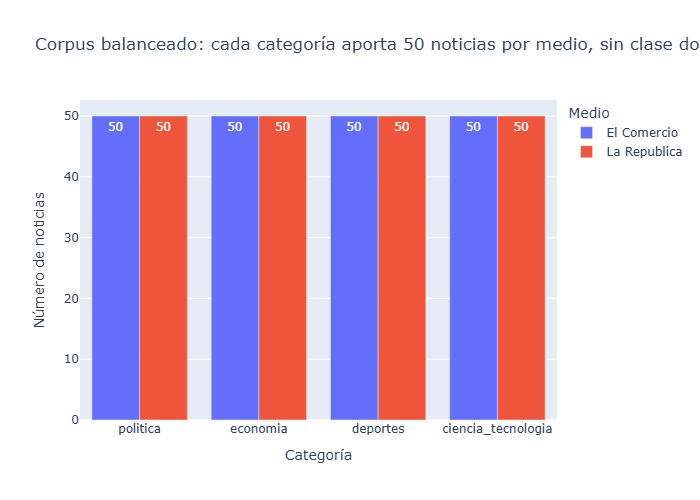

In [11]:
df["largo_titular"] = df["titular"].str.len()
df["fecha_dt"] = pd.to_datetime(df["fecha"])

conteo_cat = df.groupby(["etiqueta", "medio"]).size().reset_index(name="noticias")
minimo, maximo = conteo_cat["noticias"].min(), conteo_cat["noticias"].max()
titulo1 = (f"Corpus balanceado: cada categoría aporta {minimo} noticias por medio, sin clase dominante"
           if minimo == maximo else
           f"Corpus casi balanceado: entre {minimo} y {maximo} noticias por medio y categoría")
fig1 = px.bar(conteo_cat, x="etiqueta", y="noticias", color="medio", barmode="group", text="noticias",
              category_orders={"etiqueta": CATEGORIAS}, title=titulo1,
              labels={"etiqueta": "Categoría", "noticias": "Número de noticias", "medio": "Medio"})
fig1.show()

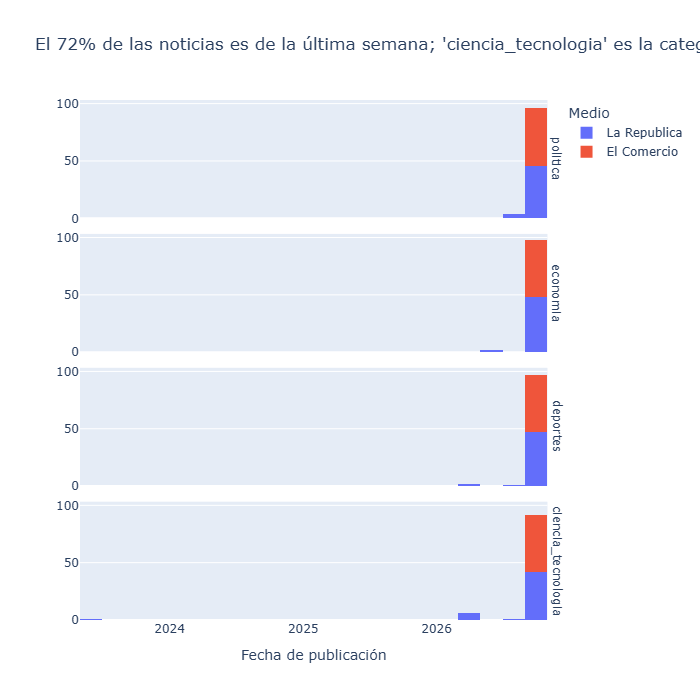

Rango de fechas por medio:


,min,max
medio,,
El Comercio,2026-10-09,2026-10-18
La Republica,2023-06-18,2026-10-18


In [12]:
ultima = df["fecha_dt"].max()
semana = (df["fecha_dt"] >= ultima - pd.Timedelta(days=6)).mean() * 100
antiguas = df.groupby("etiqueta")["fecha_dt"].median().sort_values()
titulo2 = (f"El {semana:.0f}% de las noticias es de la última semana; "
           f"'{antiguas.index[0]}' es la categoría con notas más antiguas")
fig2 = px.histogram(df, x="fecha_dt", color="medio", facet_row="etiqueta", nbins=40,
                    category_orders={"etiqueta": CATEGORIAS}, title=titulo2, height=700,
                    labels={"fecha_dt": "Fecha de publicación", "medio": "Medio"})
fig2.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig2.update_yaxes(title_text="")
fig2.show()
print("Rango de fechas por medio:")
df.groupby("medio")["fecha_dt"].agg(["min", "max"])

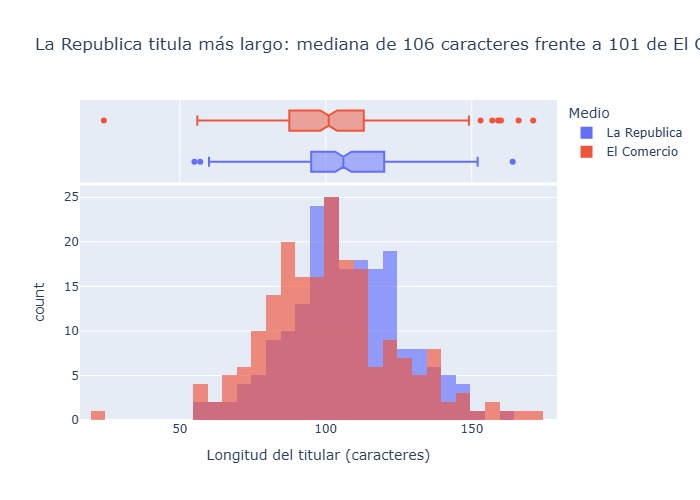

etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,96.0,100.0,94.0,112.0
La Republica,120.0,113.0,100.0,96.0


In [13]:
med = df.groupby("medio")["largo_titular"].median()
largo, corto = med.idxmax(), med.idxmin()
titulo3 = (f"{largo} titula más largo: mediana de {med[largo]:.0f} caracteres frente a {med[corto]:.0f} de {corto}"
           if med[largo] != med[corto] else f"Ambos medios titulan con la misma longitud mediana ({med[largo]:.0f} caracteres)")
fig3 = px.histogram(df, x="largo_titular", color="medio", nbins=30, barmode="overlay", opacity=0.65,
                    marginal="box", title=titulo3,
                    labels={"largo_titular": "Longitud del titular (caracteres)", "medio": "Medio"})
fig3.show()
df.groupby(["medio", "etiqueta"])["largo_titular"].median().unstack().round(0)

## 7. Validación: titulares más largos y más cortos

In [14]:
cols = ["medio", "etiqueta", "largo_titular", "titular"]
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "largo_titular")[cols])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "largo_titular")[cols])
print(f"Rango del histograma: {df['largo_titular'].min()} – {df['largo_titular'].max()} caracteres "
      f"(mediana {df['largo_titular'].median():.0f}). Los extremos listados coinciden con las colas del histograma.")

5 titulares MÁS LARGOS


,medio,etiqueta,largo_titular,titular
2507,El Comercio,deportes,171,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...
2622,El Comercio,politica,166,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a for..."
16,La Republica,ciencia_tecnologia,164,"En 1986, la explosión del reactor de Chernóbil obligó a que los perros fueran abandonados por sus dueños; décadas de..."
2618,El Comercio,politica,160,"Juan Sheput sobre eventual suspensión del viaje del papa León XIV al Perú: “Es posible, pero todavía no está la pala..."
2609,El Comercio,politica,159,Ernesto Álvarez sobre lucha contra la extorsión: “Este delito no se combate con presencia policial en la calle ni ta...


5 titulares MÁS CORTOS


,medio,etiqueta,largo_titular,titular
2638,El Comercio,economia,24,IA y Sandbox regulatorio
2237,La Republica,politica,55,Ejército simuló entrega de helicópteros rusos reparados
2413,El Comercio,deportes,56,CD Moquegua venció a FC Cajamarca por el Torneo Clausura
467,La Republica,deportes,57,¿Cuándo inicia la Liga Peruana de Vóley Femenina 2026-27?
2465,El Comercio,economia,58,Precio del dólar en Perú: cierre del domingo 18 de octubre


Rango del histograma: 24 – 171 caracteres (mediana 103). Los extremos listados coinciden con las colas del histograma.


## 8. Exportación de `datos/noticias.csv`

In [15]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df.sort_values(["medio", "etiqueta", "fecha"], ascending=[True, True, False])[COLUMNAS].reset_index(drop=True)
final.to_csv(DIR_DATOS / "noticias.csv", index=False, encoding="utf-8")
print("df.shape =", final.shape)
assert list(final.columns) == COLUMNAS and len(final) >= 350 and final["url"].is_unique
final.head(5)

df.shape = (400, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Tesla presenta un Roadster capaz de ‘volar’ y en las redes sociales lo reciben con memes,El nuevo vehículo de Elon Musk combina tecnología de SpaceX. Durante las pruebas realizó varias piruetas en el aire ...,El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/tesla-presenta-un-roadster-capaz-de-volar-y-en-las-redes-sociales-lo-rec...,2026-10-18,ciencia_tecnologia
1,Alemania investiga una presunta agresión sexual con un robot contra joven de 16 años,La agresión ocurrió en Colonia y fue transmitida en directo en redes sociales. El robot fue encontrado en la maleter...,El Comercio,tecnologia/robotica,https://elcomercio.pe/tecnologia/robotica/alemania-investiga-una-presunta-agresion-sexual-con-un-robot-contra-joven-...,2026-10-18,ciencia_tecnologia
2,Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue,"La carta abierta, que además de Yoshua Bengio incluye a especialistas en IA y ciberseguridad, remarcó incidentes don...",El Comercio,tecnologia/inteligencia-artificial,https://elcomercio.pe/tecnologia/inteligencia-artificial/padre-de-la-ia-y-otros-224-cientificos-piden-cambios-inmedi...,2026-10-18,ciencia_tecnologia
3,Descubren en los Andes peruanos una nueva flor y la bautizan en honor a Lionel Messi,Un grupo de investigadores en botánica descubrió una flor que crece en las laderas rocosas de la sierra peruana y po...,El Comercio,tecnologia/ciencias,https://elcomercio.pe/tecnologia/ciencias/salvia-messii-descubren-en-los-andes-peruanos-una-nueva-flor-y-la-bautizan...,2026-10-17,ciencia_tecnologia
4,Estafas digitales contra adultos mayores: seis recomendaciones para proteger a padres y abuelos,"Los delincuentes recurren a mensajes falsos, suplantación de identidad y hasta clonación de voz para engañar a sus v...",El Comercio,tecnologia/ciberseguridad,https://elcomercio.pe/tecnologia/ciberseguridad/estafas-digitales-contra-adultos-mayores-seis-recomendaciones-para-p...,2026-10-17,ciencia_tecnologia


**Comprobación de URLs funcionales:** se verifica con `HEAD` una muestra aleatoria de 10 URLs (respetando pausas).

In [16]:
muestra = final.sample(10, random_state=1)
estados = []
for u in muestra["url"]:
    try:
        estados.append(SESSION.head(u, timeout=20, allow_redirects=True).status_code)
    except requests.RequestException:
        estados.append(None)
    time.sleep(random.uniform(1, 2))
muestra = muestra.assign(http=estados)[["medio", "url", "http"]]
print(f"{(muestra['http'] == 200).sum()}/10 URLs responden 200")
muestra

10/10 URLs responden 200


,medio,url,http
398,La Republica,https://larepublica.pe/politica/2026/08/03/poder-judicial-condena-a-cesar-acuna-a-un-ano-y-medio-de-prision-suspendi...,200
125,El Comercio,https://elcomercio.pe/economia/indecopi-se-pronuncia-sobre-presunta-filtracion-de-datos-en-interseguro-noticia/,200
328,La Republica,https://larepublica.pe/economia/precio-del-dolar/2026/10/02/precio-del-dolar-hoy-en-peru-viernes-2-de-octubre-asi-ce...,200
339,La Republica,https://larepublica.pe/economia/2026/09/23/cut-peru-rechaza-supuesto-respaldo-unanime-a-candidatura-de-gonzalezolaec...,200
172,El Comercio,https://elcomercio.pe/politica/grupos-hostiles-mecanismos-antiterroristas-y-el-factor-dini-estos-son-los-nuevos-punt...,200
342,La Republica,https://larepublica.pe/economia/2026/09/22/sueldo-minimo-que-pasara-despues-de-los-s1300-sheput-anuncia-nueva-formul...,200
197,El Comercio,https://elcomercio.pe/politica/las-nuevas-bancadas-cascaron-votaciones-en-temas-oficialistas-muestran-fisuras-en-gru...,200
291,La Republica,https://larepublica.pe/deportes/2026/10/06/universitario-melgar-fecha-hora-y-canal-del-partido-por-la-fecha-11-del-t...,200
29,El Comercio,https://elcomercio.pe/tecnologia/gadgets/google-lanza-fitbit-edge-una-pulsera-avanzada-de-salud-con-bateria-para-una...,200
284,La Republica,https://larepublica.pe/deportes/2026/10/09/tabla-de-posiciones-del-sudamericano-de-voley-sub19-resultados-y-partidos...,200


## Conclusiones de la Parte 1

- Se construyó un corpus comparado de **400 noticias** (200 por medio, 50 por categoría y medio) con las 7 columnas requeridas.
- La República exigió una estrategia distinta a El Comercio: su `robots.txt` prohíbe la paginación, así que se combinaron
  RSS, portadas de sección y bloques de "más noticias de la sección". El Comercio expone sitemaps por sección que se
  complementaron con los metadatos `og:` de cada artículo.
- Todas las noticias fuera de las 4 categorías se descartaron y quedaron reportadas en la tabla de descartes.